

<div dir="rtl" style="text-align: right;">

# تشخیص حروف فارسی
این پروژه ۳۲ حرف مستقل را با SVM، KNN و Random Forest تشخیص می‌دهد. معیار اصلی تنظیم پارامترها و انتخاب مدل **Accuracy اعتبارسنجی** است. تصاویر با فونت تولید می‌شوند؛ این داده‌ها دست‌خط واقعی افراد نیستند.

تغییرات: اندازه ورودی ثابت ۳۲×۳۲، یک اندازه پایه فونت، بولد مصنوعی، چرخش ±۵ درجه، جابه‌جایی، Scale و جست‌وجوی پارامترهای بیشتر. فونت‌های خوشنویسی به‌عنوان سبک کمکی معرفی شده‌اند، نه نویسنده واقعی.

</div>


<div dir="rtl" style="text-align: right;">

## ۱. باز کردن پروژه در Colab
</div>

In [1]:
from google.colab import files
from pathlib import Path
import zipfile
uploaded_project = files.upload()
zip_paths = [Path(name) for name in uploaded_project if name.lower().endswith('.zip')]
if len(zip_paths) != 1:
    raise ValueError('فقط یک ZIP پروژه را آپلود کن.')
with zipfile.ZipFile(zip_paths[0]) as archive:
    archive.extractall('/content/persian_handwriting_project')
%cd /content/persian_handwriting_project/Persian_Handwriting


Saving Persian_Handwriting_Improved.zip to Persian_Handwriting_Improved.zip
/content/persian_handwriting_project/Persian_Handwriting


In [2]:
%pip install -q -r requirements.txt


In [3]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, GridSearchCV, ParameterGrid
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay
import joblib

ROOT = Path.cwd()
assert (ROOT/'fonts').is_dir() and (ROOT/'generate_dataset.py').is_file(), 'ابتدا وارد پوشه پروژه شو.'
RANDOM_STATE = 42
N_JOBS = 1  # اجرای کم‌حافظه؛ در Colab با RAM کافی می‌توان 2 قرار داد.



<div dir="rtl" style="text-align: right;">

## ۲. ساخت یا خواندن دیتاست
اندازه پایه فونت ۴۸ است و همه ورودی‌ها ۳۲×۳۲ هستند. ابتدا حرف و نقطه‌ها در قاب جا می‌گیرند، سپس تغییرات ساخته می‌شوند. هر حرف/فونت یک اصل و ۳۰ نسخه تغییریافته دارد: ۲ حالت ضخامت × ۳ زاویه × ۵ Scale؛ Shiftهای مشخص بین ترکیب‌ها می‌چرخند.

Scaleهای `11/12` و `13/12` همان نسبت تغییر اندازه ۱۲ به ۱۱ و ۱۳ هستند؛ به معنی رندر واقعی فونت در ۱۱ و ۱۳ پیکسل نیستند. رندر کم‌وضوح ممکن است نقطه‌ها را خراب کند. بعد از تغییرات، دیگر Crop یا مرکزگذاری نمی‌کنیم تا اثر Scale و Shift حفظ شود. بولد، افزایش مصنوعی ضخامت است؛ فونت Bold مستقل محسوب نمی‌شود.

</div>

In [4]:
REGENERATE = False
from generate_dataset import generate, BASE_FONT_SIZE, ANGLES, SCALES

data_path = ROOT/'dataset_augmented'
if REGENERATE or not (data_path/'metadata.csv').is_file():
    generate(data_path)

data = pd.read_csv(data_path/'metadata.csv')
classes = json.loads((data_path/'classes.json').read_text(encoding='utf-8'))
classes_table = pd.DataFrame(classes)
report = json.loads((data_path/'generation_report.json').read_text(encoding='utf-8'))
print('Fonts:', data['font'].nunique())
print('Images:', len(data))
print('Classes:', data['label'].nunique())
print('Samples per font/letter:', sorted(data.groupby(['font','label']).size().unique()))
display(classes_table)
display(data.head())


Fonts: 8
Images: 7936
Classes: 32
Samples per font/letter: [np.int64(31)]


,label,char,name
0,0,ا,alef
1,1,ب,be
2,2,پ,pe
3,3,ت,te
4,4,ث,se
5,5,ج,jim
6,6,چ,che
7,7,ح,he_jimi
8,8,خ,khe
9,9,د,dal


,path,label,char,font,source_id,is_original,base_font_size,synthetic_bold,angle,scale,shift_x,shift_y
0,images/DastNevis/00_alef/00.png,0,ا,DastNevis,DastNevis:0,True,48,False,0,1.000000,0,0
1,images/DastNevis/00_alef/01.png,0,ا,DastNevis,DastNevis:0,False,48,False,-5,0.800000,-2,0
2,images/DastNevis/00_alef/02.png,0,ا,DastNevis,DastNevis:0,False,48,False,-5,0.916667,2,0
3,images/DastNevis/00_alef/03.png,0,ا,DastNevis,DastNevis:0,False,48,False,-5,1.000000,0,-2
4,images/DastNevis/00_alef/04.png,0,ا,DastNevis,DastNevis:0,False,48,False,-5,1.083333,0,2


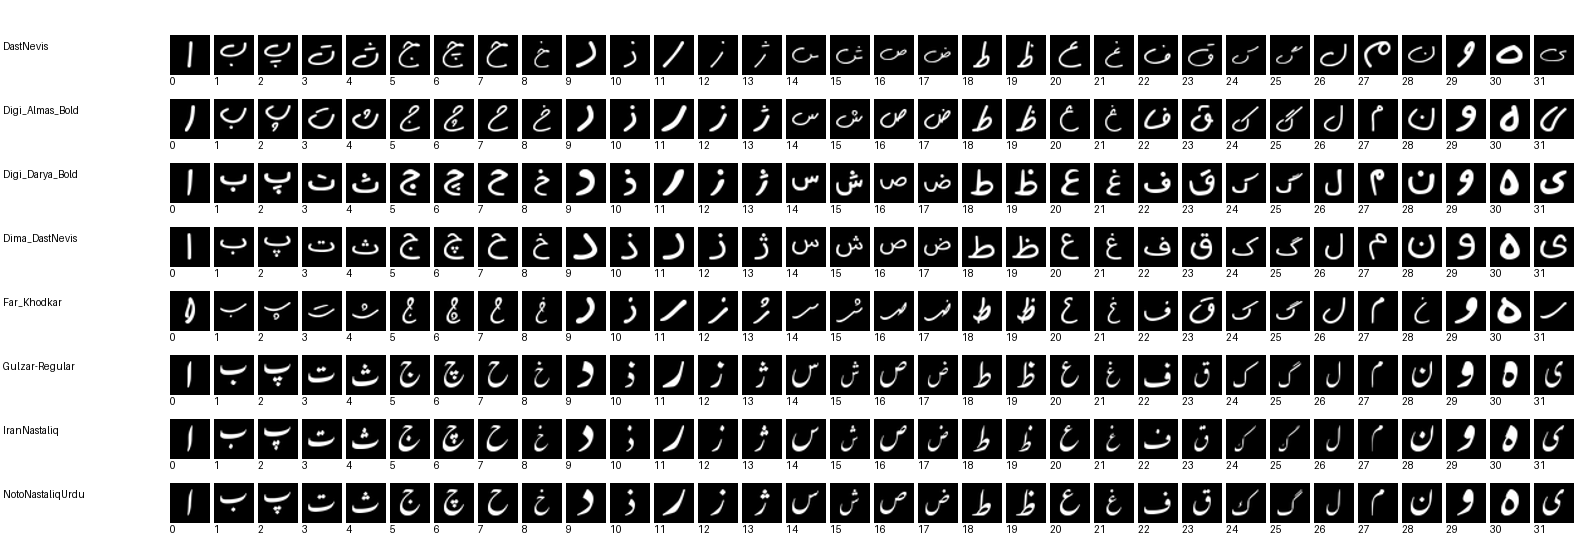

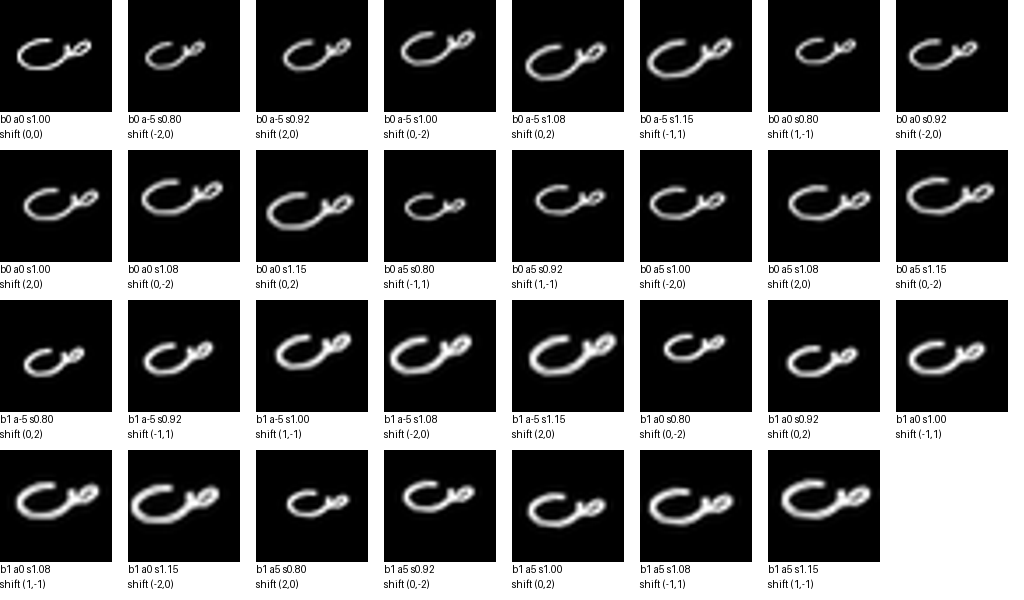

In [5]:
display(Image.open(data_path/'font_preview.png'))
display(Image.open(data_path/'augmentation_preview.png'))




<div dir="rtl" style="text-align: right;">

## ۳. خواندن ویژگی‌های پیکسلی
تصاویر از قبل به اندازه ۳۲×۳۲ آماده شده‌اند. آن‌ها را مستقیم می‌خوانیم؛ استفاده دوباره از مرکزگذاری باعث حذف تنوع جابه‌جایی و اندازه می‌شود. مقادیر را بر ۲۵۵ تقسیم و هر تصویر را به بردار ۱۰۲۴تایی تبدیل می‌کنیم.
</div>


In [6]:
images = []
for path in data['path']:
    with Image.open(data_path/path) as image:
        assert image.size == (32, 32)
        images.append(np.array(image.convert('L'), dtype=np.float32)/255.0)
images = np.stack(images)
X = images.reshape(len(images), -1)
y = data['label'].to_numpy()
fonts = data['font'].to_numpy()
original = data['is_original'].to_numpy(dtype=bool)
print('X:', X.shape, 'y:', y.shape)


X: (7936, 1024) y: (7936,)



<div dir="rtl" style="text-align: right;">

## ۴. جداسازی تست بر اساس فونت، قبل از انتخاب پارامترها
با Seed ثابت، ۲۰٪ از خانواده‌های فونت کنار گذاشته می‌شوند. تمام حالت‌های یک فونت در یک سمت می‌مانند. آموزش از اصل و نسخه‌های تغییریافته فونت‌های آموزش استفاده می‌کند؛ تست اصلی فقط حروف **بدون تغییرِ فونت‌های ندیده** است. نسخه‌های تغییریافته فونت تست استفاده نمی‌شوند.

این سنجش انتقال به فونت جدید است و معادل دقت دست‌خط انسان نیست. با تعداد کم فونت، نتیجه به فونت‌های کنارگذاشته‌شده حساس است؛ بعد از دیدن تست، Seed را برای بهترشدن عدد تغییر نده.

</div>


In [7]:
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
train_indices, heldout_indices = next(splitter.split(X, y, groups=fonts))
test_indices = heldout_indices[original[heldout_indices]]
X_train, y_train = X[train_indices], y[train_indices]
X_test, y_test = X[test_indices], y[test_indices]
train_fonts = fonts[train_indices]
train_original = original[train_indices]
assert set(train_fonts).isdisjoint(set(fonts[test_indices]))
assert set(y_train) == set(y_test) == set(classes_table['label'])
print('Train:', X_train.shape, 'Test:', X_test.shape)
print('Training fonts:', sorted(set(train_fonts)))
print('Held-out fonts:', sorted(set(fonts[test_indices])))


Train: (5952, 1024) Test: (64, 1024)
Training fonts: ['DastNevis', 'Digi_Darya_Bold', 'Dima_DastNevis', 'Far_Khodkar', 'IranNastaliq', 'NotoNastaliqUrdu']
Held-out fonts: ['Digi_Almas_Bold', 'Gulzar-Regular']



<div dir="rtl" style="text-align: right;">

## ۵. اعتبارسنجی گروهی با Accuracy
در هر Fold، چند فونت کامل کنار گذاشته می‌شود. فقط نمونه‌های اصلی این فونت‌ها برای اعتبارسنجی استفاده می‌شوند و نمونه‌های تغییریافته آن‌ها در آموزش همان Fold نیستند. بنابراین نسخه چرخیده یک حرف نمی‌تواند جواب نسخه اصلی همان فونت را به مدل لو بدهد.

StandardScaler داخل Pipeline است و فقط با آموزش هر Fold برازش می‌شود. بهترین تنظیمات با میانگین Accuracy این Foldها تعیین و سپس روی تمام داده آموزش برازش می‌شوند. تست نهایی در این فرآیند دخالت ندارد.

</div>


In [8]:
n_folds = min(4, len(set(train_fonts)))
if n_folds < 2:
    raise ValueError('برای اعتبارسنجی گروهی فونت بیشتری لازم است.')
validation_split = []
for fit_idx, val_all in GroupKFold(n_splits=n_folds).split(X_train, y_train, train_fonts):
    val_idx = val_all[train_original[val_all]]
    assert set(train_fonts[fit_idx]).isdisjoint(set(train_fonts[val_idx]))
    assert set(y_train[fit_idx]) == set(y_train[val_idx]) == set(y_train)
    validation_split.append((fit_idx, val_idx))
    print('Fit:', len(fit_idx), 'Validation originals:', len(val_idx),
          'Validation fonts:', sorted(set(train_fonts[val_idx])))


Fit: 3968 Validation originals: 64 Validation fonts: ['Digi_Darya_Bold', 'NotoNastaliqUrdu']
Fit: 3968 Validation originals: 64 Validation fonts: ['DastNevis', 'IranNastaliq']
Fit: 4960 Validation originals: 32 Validation fonts: ['Far_Khodkar']
Fit: 4960 Validation originals: 32 Validation fonts: ['Dima_DastNevis']




<div dir="rtl" style="text-align: right;">

## ۶. تعریف مدل‌ها و محدوده پارامترها
**SVM:** مقادیر C زیر ۱ هم بررسی می‌شوند، همراه چند gamma.

**KNN:** تعداد همسایه‌ها شامل ۱۰، ۲۰، ۵۰ و ۱۰۰ است؛ وزن‌دهی و فاصله منهتن/اقلیدسی هم بررسی می‌شوند. KNN پارامتر `max_depth` و `min_samples_split` ندارد؛ این‌ها در Random Forest تنظیم می‌شوند. KNN درخت تصمیم نیست، حتی اگر برای جست‌وجوی همسایه‌ها از ساختمان داده درخت استفاده کند.

**Random Forest:** تعداد درخت‌ها ۱۰۰، ۲۰۰ و ۵۰۰؛ عمق، حداقل نمونه برای Split و حداقل نمونه برگ.

</div>


In [9]:
svm_pipeline = Pipeline([('scaler', StandardScaler()), ('model', SVC())])
svm_parameters = {
    'model__C': [0.01, 0.1, 0.5, 1, 5, 10, 50, 100],
    'model__gamma': ['scale', 0.0001, 0.001, 0.01],
    'model__kernel': ['rbf']
}

knn_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', KNeighborsClassifier(algorithm='brute', n_jobs=1))
])
knn_parameters = {
    'model__n_neighbors': [1, 3, 5, 10, 20, 50, 100],
    'model__weights': ['uniform', 'distance'],
    'model__p': [1, 2]
}
# تعداد همسایه از تعداد داده آموزش کوچک‌ترین Fold بیشتر نباشد.
smallest_fold = min(len(fit) for fit, val in validation_split)
knn_parameters['model__n_neighbors'] = [
    k for k in knn_parameters['model__n_neighbors'] if k <= smallest_fold
]

rf_pipeline = Pipeline([
    ('model', RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1))
])
rf_parameters = {
    'model__n_estimators': [100, 200, 500],
    'model__max_depth': [None, 10, 20, 50],
    'model__min_samples_split': [2, 5, 10],
    'model__min_samples_leaf': [1, 2]
}

for name, params in [('SVM', svm_parameters), ('KNN', knn_parameters), ('Random Forest', rf_parameters)]:
    print(name, ':', len(ParameterGrid(params)), 'combinations;',
          len(ParameterGrid(params))*n_folds, 'CV fits + one final refit')


SVM : 32 combinations; 128 CV fits + one final refit
KNN : 28 combinations; 112 CV fits + one final refit
Random Forest : 72 combinations; 288 CV fits + one final refit



<div dir="rtl" style="text-align: right;">

## ۷. آموزش SVM
امتیاز `mean_test_score` در جدول GridSearch، Accuracy **اعتبارسنجی** است؛ این نام داخلی کتابخانه به تست نهایی اشاره ندارد.

</div>


In [10]:
svm_search = GridSearchCV(
    svm_pipeline, svm_parameters,
    scoring='accuracy', cv=validation_split, refit=True,
    n_jobs=N_JOBS, pre_dispatch=N_JOBS, verbose=1, error_score='raise'
)
svm_search.fit(X_train, y_train)
svm_model = svm_search.best_estimator_
print('Best parameters:', svm_search.best_params_)
print('Validation Accuracy:', svm_search.best_score_)
display(pd.DataFrame(svm_search.cv_results_)[
    ['params', 'mean_test_score', 'std_test_score', 'rank_test_score']
].sort_values('rank_test_score').head(10))


Fitting 4 folds for each of 32 candidates, totalling 128 fits
Best parameters: {'model__C': 5, 'model__gamma': 'scale', 'model__kernel': 'rbf'}
Validation Accuracy: 0.71484375


,params,mean_test_score,std_test_score,rank_test_score
18,"{'model__C': 5, 'model__gamma': 0.001, 'model_...",0.714844,0.084415,1
16,"{'model__C': 5, 'model__gamma': 'scale', 'mode...",0.714844,0.084415,1
12,"{'model__C': 1, 'model__gamma': 'scale', 'mode...",0.687500,0.090436,3
21,"{'model__C': 10, 'model__gamma': 0.0001, 'mode...",0.687500,0.086292,3
14,"{'model__C': 1, 'model__gamma': 0.001, 'model_...",0.683594,0.084415,5
20,"{'model__C': 10, 'model__gamma': 'scale', 'mod...",0.679688,0.087346,6
24,"{'model__C': 50, 'model__gamma': 'scale', 'mod...",0.679688,0.101562,6
22,"{'model__C': 10, 'model__gamma': 0.001, 'model...",0.679688,0.087346,6
26,"{'model__C': 50, 'model__gamma': 0.001, 'model...",0.679688,0.101562,6
25,"{'model__C': 50, 'model__gamma': 0.0001, 'mode...",0.675781,0.087956,10


## ۸. آموزش KNN


In [11]:
knn_search = GridSearchCV(
    knn_pipeline, knn_parameters,
    scoring='accuracy', cv=validation_split, refit=True,
    n_jobs=N_JOBS, pre_dispatch=N_JOBS, verbose=1, error_score='raise'
)
knn_search.fit(X_train, y_train)
knn_model = knn_search.best_estimator_
print('Best parameters:', knn_search.best_params_)
print('Validation Accuracy:', knn_search.best_score_)
display(pd.DataFrame(knn_search.cv_results_)[
    ['params', 'mean_test_score', 'std_test_score', 'rank_test_score']
].sort_values('rank_test_score').head(10))


Fitting 4 folds for each of 28 candidates, totalling 112 fits
Best parameters: {'model__n_neighbors': 5, 'model__p': 2, 'model__weights': 'uniform'}
Validation Accuracy: 0.5703125


,params,mean_test_score,std_test_score,rank_test_score
15,"{'model__n_neighbors': 10, 'model__p': 2, 'mod...",0.570312,0.102162,1
10,"{'model__n_neighbors': 5, 'model__p': 2, 'mode...",0.570312,0.071175,1
11,"{'model__n_neighbors': 5, 'model__p': 2, 'mode...",0.558594,0.084415,3
14,"{'model__n_neighbors': 10, 'model__p': 2, 'mod...",0.558594,0.090013,3
19,"{'model__n_neighbors': 20, 'model__p': 2, 'mod...",0.558594,0.081471,3
18,"{'model__n_neighbors': 20, 'model__p': 2, 'mod...",0.554688,0.078515,6
13,"{'model__n_neighbors': 10, 'model__p': 1, 'mod...",0.542969,0.112334,7
7,"{'model__n_neighbors': 3, 'model__p': 2, 'mode...",0.535156,0.092686,8
2,"{'model__n_neighbors': 1, 'model__p': 2, 'mode...",0.523438,0.105106,9
17,"{'model__n_neighbors': 20, 'model__p': 1, 'mod...",0.523438,0.063948,9


## ۹. آموزش Random Forest


In [12]:
rf_search = GridSearchCV(
    rf_pipeline, rf_parameters,
    scoring='accuracy', cv=validation_split, refit=True,
    n_jobs=N_JOBS, pre_dispatch=N_JOBS, verbose=1, error_score='raise'
)
rf_search.fit(X_train, y_train)
rf_model = rf_search.best_estimator_
print('Best parameters:', rf_search.best_params_)
print('Validation Accuracy:', rf_search.best_score_)
display(pd.DataFrame(rf_search.cv_results_)[
    ['params', 'mean_test_score', 'std_test_score', 'rank_test_score']
].sort_values('rank_test_score').head(10))


Fitting 4 folds for each of 72 candidates, totalling 288 fits
Best parameters: {'model__max_depth': None, 'model__min_samples_leaf': 2, 'model__min_samples_split': 2, 'model__n_estimators': 500}
Validation Accuracy: 0.70703125


,params,mean_test_score,std_test_score,rank_test_score
11,"{'model__max_depth': None, 'model__min_samples...",0.707031,0.118675,1
65,"{'model__max_depth': 50, 'model__min_samples_l...",0.707031,0.118675,1
59,"{'model__max_depth': 50, 'model__min_samples_l...",0.699219,0.118675,3
5,"{'model__max_depth': None, 'model__min_samples...",0.699219,0.118675,3
47,"{'model__max_depth': 20, 'model__min_samples_l...",0.695312,0.119763,5
14,"{'model__max_depth': None, 'model__min_samples...",0.695312,0.109096,5
68,"{'model__max_depth': 50, 'model__min_samples_l...",0.695312,0.109096,5
44,"{'model__max_depth': 20, 'model__min_samples_l...",0.691406,0.102683,8
38,"{'model__max_depth': 20, 'model__min_samples_l...",0.691406,0.103865,8
63,"{'model__max_depth': 50, 'model__min_samples_l...",0.691406,0.090013,8



<div dir="rtl" style="text-align: right;">

## ۱۰. انتخاب مدل بر اساس Accuracy اعتبارسنجی
مدل منتخب پیش از دیدن نتیجه تست انتخاب می‌شود. در تساوی، ترتیب ثابت SVM، KNN و Random Forest ملاک است.
</div>

,Model,Validation Accuracy,CV std,Best parameters
0,SVM,0.714844,0.084415,"{'model__C': 5, 'model__gamma': 'scale', 'mode..."
1,KNN,0.570312,0.071175,"{'model__n_neighbors': 5, 'model__p': 2, 'mode..."
2,Random Forest,0.707031,0.118675,"{'model__max_depth': None, 'model__min_samples..."


Selected: SVM


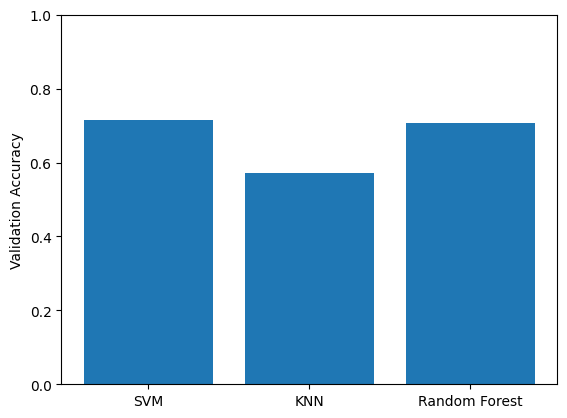

In [13]:
searches = {'SVM': svm_search, 'KNN': knn_search, 'Random Forest': rf_search}
validation_results = pd.DataFrame([
    {'Model': name, 'Validation Accuracy': search.best_score_,
     'CV std': search.cv_results_['std_test_score'][search.best_index_],
     'Best parameters': search.best_params_}
    for name, search in searches.items()
])
best_index = validation_results['Validation Accuracy'].idxmax()
best_name = validation_results.loc[best_index, 'Model']
best_model = searches[best_name].best_estimator_
display(validation_results)
print('Selected:', best_name)
plt.bar(validation_results['Model'], validation_results['Validation Accuracy'])
plt.ylim(0, 1)
plt.ylabel('Validation Accuracy')
plt.show()


## ۱۱. ارزیابی نهایی روی فونت‌های ندیده
اکنون تست را ارزیابی می‌کنیم. نتیجه تست معیار تغییر پارامترها یا عوض‌کردن مدل منتخب نیست. Accuracy معیار اصلی و Error برابر ۱ منهای آن است؛ Macro-F1 فقط اطلاعات تکمیلی است. تعداد نمونه تست کوچک است؛ تعداد پاسخ درست/کل هم گزارش می‌شود.


,Model,Test Accuracy,Test Error,Test Macro-F1,Correct,Total
0,SVM,0.828125,0.171875,0.812500,53,64
1,KNN,0.656250,0.343750,0.616815,42,64
2,Random Forest,0.828125,0.171875,0.821875,53,64


              precision    recall  f1-score   support

        alef       1.00      1.00      1.00         2
          be       1.00      1.00      1.00         2
          pe       1.00      1.00      1.00         2
          te       1.00      0.50      0.67         2
          se       1.00      0.50      0.67         2
         jim       1.00      1.00      1.00         2
         che       1.00      1.00      1.00         2
     he_jimi       0.67      1.00      0.80         2
         khe       0.50      0.50      0.50         2
         dal       1.00      1.00      1.00         2
         zal       1.00      1.00      1.00         2
          re       1.00      1.00      1.00         2
          ze       0.67      1.00      0.80         2
         zhe       1.00      0.50      0.67         2
         sin       1.00      0.50      0.67         2
        shin       0.67      1.00      0.80         2
         sad       0.67      1.00      0.80         2
         zad       1.00    

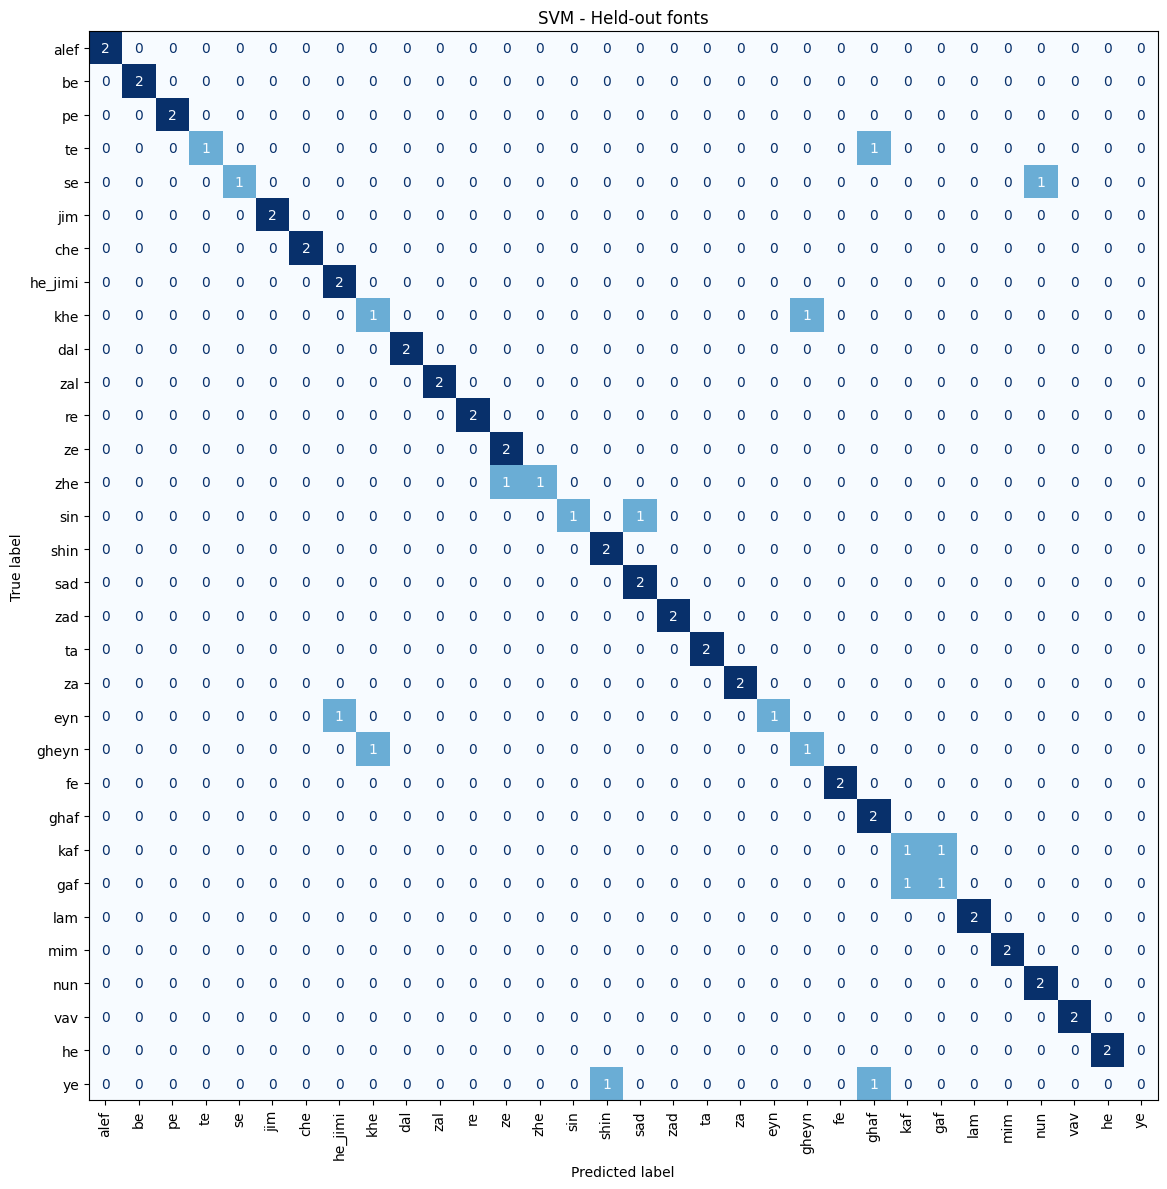

In [14]:
test_rows = []
predictions = {}
for name, search in searches.items():
    pred = search.best_estimator_.predict(X_test)
    predictions[name] = pred
    test_rows.append({
        'Model': name, 'Test Accuracy': accuracy_score(y_test, pred),
        'Test Error': 1-accuracy_score(y_test, pred),
        'Test Macro-F1': f1_score(y_test, pred, average='macro', zero_division=0),
        'Correct': int((pred == y_test).sum()), 'Total': len(y_test)
    })
test_results = pd.DataFrame(test_rows)
display(test_results)
y_pred = predictions[best_name]
print(classification_report(y_test, y_pred,
      labels=classes_table['label'].tolist(),
      target_names=classes_table['name'].tolist(), zero_division=0))
fig, ax = plt.subplots(figsize=(14, 12))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, labels=classes_table['label'].tolist(),
    display_labels=classes_table['name'].tolist(), cmap='Blues',
    xticks_rotation=90, colorbar=False, ax=ax)
plt.title(best_name+' - Held-out fonts')
plt.tight_layout()
plt.show()


<div dir="rtl" style="text-align: right;">

## ۱۲. آزمایش عکس یک حرف دست‌نویس

</div>


In [15]:
import cv2
import numpy as np
from PIL import Image, ImageOps


def prepare_photo(image, min_contrast=18):
    """Clean one dark handwritten letter on plain light paper."""
    image = ImageOps.exif_transpose(image).convert('RGB')
    image.thumbnail((800, 800))
    gray = cv2.cvtColor(np.array(image), cv2.COLOR_RGB2GRAY)

    # کاهش نویز ریز عکس، بدون پاک‌کردن نقطه‌ها با عملیات opening
    gray = cv2.GaussianBlur(gray, (3, 3), 0)

    # تخمین روشنایی کاغذ و کاهش اثر سایه
    kernel_size = max(15, min(gray.shape) // 12)
    kernel_size = kernel_size // 2 * 2 + 1
    kernel = np.ones((kernel_size, kernel_size), dtype=np.uint8)
    background = cv2.morphologyEx(gray, cv2.MORPH_CLOSE, kernel)
    background = np.maximum(background, 1)
    corrected = cv2.divide(gray, background, scale=255)

    # جوهر سفید و زمینه سیاه می‌شود
    ink = 255 - corrected
    otsu_threshold, _ = cv2.threshold(
        ink, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )
    threshold = max(min_contrast, otsu_threshold)
    mask = np.uint8(ink > threshold) * 255

    # جداسازی اجزای تصویر: بدنه حرف، نقطه‌ها و نویزها
    count, components, stats, _ = cv2.connectedComponentsWithStats(mask, 8)
    if count <= 1:
        raise ValueError('حرفی پیدا نشد؛ عکس واضح‌تر یا min_contrast کمتر را امتحان کنید.')

    main = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
    x, y, width, height, area = stats[main]
    if area < 8:
        raise ValueError('نوشته بسیار کوچک یا کم‌رنگ است.')

    # اجزای نزدیک بدنه را نگه می‌داریم تا نقطه‌ها حذف نشوند
    clean = np.zeros_like(mask)
    margin = max(width, height) * 0.8
    min_area = max(2, area * 0.01)

    for i in range(1, count):
        left, top, w, h, size = stats[i]
        gap_x = max(x - (left + w), left - (x + width), 0)
        gap_y = max(y - (top + h), top - (y + height), 0)

        if size >= min_area and gap_x <= margin and gap_y <= margin:
            clean[components == i] = 255

    # همان اندازه و مرکزگذاری مورد استفاده در آموزش
    rows, columns = np.where(clean > 0)
    cropped = clean[rows.min():rows.max()+1, columns.min():columns.max()+1]
    letter = Image.fromarray(cropped)
    letter.thumbnail((21, 21), Image.Resampling.LANCZOS)
    canvas = Image.new('L', (32, 32), 0)
    x = (32 - letter.width) // 2
    y = (32 - letter.height) // 2
    canvas.paste(letter, (x, y))
    prepared = np.array(canvas) / 255.0
    return prepared, corrected, clean


In [18]:
from google.colab import files
uploaded = files.upload()
photo_path = next(iter(uploaded), '')


Saving 496_Char_20.png to 496_Char_20.png


Predicted letter: ذ
Letter name: zal


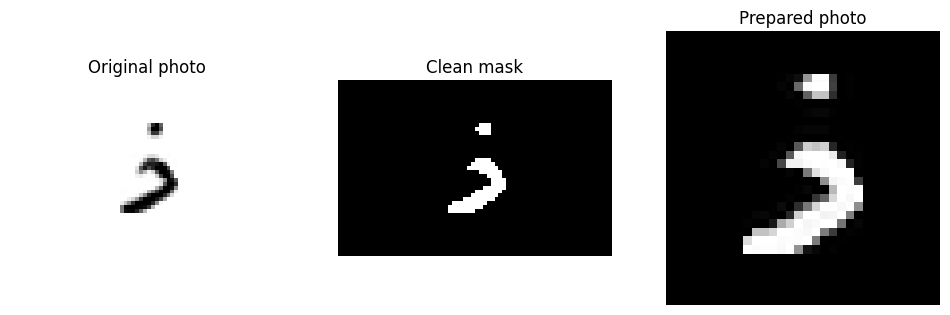

In [19]:
if photo_path != '':
    with Image.open(photo_path) as photo:
        original_photo = ImageOps.exif_transpose(photo).convert('RGB')
        prepared_photo, corrected_photo, clean_mask = prepare_photo(original_photo)

    photo_features = prepared_photo.reshape(1, 1024)

    # Pipeline استانداردسازی لازم را خودش انجام می‌دهد

    predicted_label = int(best_model.predict(photo_features)[0])
    predicted_letter = classes[predicted_label]['char']

    print('Predicted letter:', predicted_letter)
    print('Letter name:', classes[predicted_label]['name'])

    plt.figure(figsize=(12, 4))

    plt.subplot(1, 3, 1)
    plt.imshow(original_photo)
    plt.title('Original photo')
    plt.axis('off')

    plt.subplot(1, 3, 2)
    plt.imshow(clean_mask, cmap='gray', vmin=0, vmax=255)
    plt.title('Clean mask')
    plt.axis('off')

    plt.subplot(1, 3, 3)
    plt.imshow(prepared_photo, cmap='gray')
    plt.title('Prepared photo')
    plt.axis('off')

    plt.show()
else:
    print('برای تست دست‌خط، مسیر عکس را در photo_path وارد کنید.')



<div dir="rtl" style="text-align: right;">

## ۱۳. ذخیره مدل و نتایج
فقط بعد از اجرای آموزش، فایل مدل و جدول‌های واقعی ذخیره می‌شوند. مدل منتخب فقط فونت‌های آموزش را دیده است؛ تست وارد آموزش نمی‌شود. جزئیات Split و تمام نتایج GridSearch هم ذخیره می‌شوند. برای استفاده بعدی، همان توابع آماده‌سازی عکس و نگاشت کلاس‌ها لازم‌اند.

</div>


In [20]:
results = ROOT/'results'
results.mkdir(exist_ok=True)
validation_results.to_csv(results/'validation_results.csv', index=False)
test_results.to_csv(results/'test_results.csv', index=False)
for name, search in searches.items():
    pd.DataFrame(search.cv_results_).to_csv(results/(name.replace(' ', '_')+'_grid.csv'), index=False)
joblib.dump(best_model, results/'model.joblib')
settings = {
    'model_name': best_name, 'selection_metric': 'accuracy',
    'image_size': 32, 'base_font_size': BASE_FONT_SIZE,
    'split_method': 'font groups; 20% held out; originals only for validation/test',
    'cv_folds': n_folds, 'random_state': RANDOM_STATE,
    'training_fonts': sorted(set(train_fonts)),
    'test_fonts': sorted(set(fonts[test_indices])),
    'train_samples': len(train_indices), 'test_samples': len(test_indices),
    'best_parameters': searches[best_name].best_params_, 'classes': classes,
    'augmentation': report
}
(results/'settings.json').write_text(json.dumps(settings, ensure_ascii=False, indent=2), encoding='utf-8')
split_names = np.full(len(data), 'unused_heldout_augmentation', dtype=object)
split_names[train_indices] = 'train'
split_names[test_indices] = 'test'
data.assign(split=split_names).to_csv(results/'data_split.csv', index=False)
print('Saved:', results)


Saved: /content/persian_handwriting_project/Persian_Handwriting/results
